In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")
orders = pd.read_csv("orders.csv")

In [5]:
print(customers.head())
print(products.head())
print(orders.head())

   customer_id           name       city        state signup_date
0            1   Aarav Sharma      Delhi        Delhi  2024-04-12
1            2  Vivaan Sharma     Mumbai  Maharashtra  2024-12-14
2            3  Aditya Sharma       Pune  Maharashtra  2024-09-27
3            4   Arjun Sharma  Bengaluru    Karnataka  2024-04-16
4            5   Rahul Sharma  Hyderabad    Telangana  2024-03-12
   product_id   product_name     category  price
0         101         Laptop  Electronics  55000
1         102  Gaming Laptop  Electronics  85000
2         103     Smartphone  Electronics  30000
3         104         Tablet  Electronics  22000
4         105     Smartwatch  Electronics   7000
   order_id  customer_id  product_id  order_date  quantity payment_method
0      1001          130         138  2025-04-11         1    Net Banking
1      1002          187         132  2025-05-10         2            UPI
2      1003          129         115  2025-05-10         2    Credit Card
3      1004   

In [6]:
print(customers.shape)
print(products.shape)
print(orders.shape)

(200, 5)
(50, 4)
(1000, 6)


In [7]:
customers.info()
products.info()
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  200 non-null    int64
 1   name         200 non-null    str  
 2   city         200 non-null    str  
 3   state        200 non-null    str  
 4   signup_date  200 non-null    str  
dtypes: int64(1), str(4)
memory usage: 7.9 KB
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   product_id    50 non-null     int64
 1   product_name  50 non-null     str  
 2   category      50 non-null     str  
 3   price         50 non-null     int64
dtypes: int64(2), str(2)
memory usage: 1.7 KB
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   order_id     

In [8]:
print(customers.isnull().sum())
print(products.isnull().sum())
print(orders.isnull().sum())

customer_id    0
name           0
city           0
state          0
signup_date    0
dtype: int64
product_id      0
product_name    0
category        0
price           0
dtype: int64
order_id          0
customer_id       0
product_id        0
order_date        0
quantity          0
payment_method    0
dtype: int64


In [9]:
print("Customers Duplicate :",customers.duplicated().sum())
print("Products Duplicate :",products.duplicated().sum())
print("Order Duplicate :",orders.isnull().sum())

Customers Duplicate : 0
Products Duplicate : 0
Order Duplicate : order_id          0
customer_id       0
product_id        0
order_date        0
quantity          0
payment_method    0
dtype: int64


In [10]:
print(customers.tail())
print(products.tail())
print(orders.tail())

     customer_id           name       city        state signup_date
195          196   Sakshi Verma  Bengaluru    Karnataka  2024-04-22
196          197    Palak Verma  Hyderabad    Telangana  2024-11-13
197          198     Diya Verma    Chennai   Tamil Nadu  2024-02-21
198          199  Radhika Verma    Kolkata  West Bengal  2024-09-24
199          200   Anjali Verma  Ahmedabad      Gujarat  2024-10-21
    product_id   product_name        category  price
45         146   Water Bottle  Home & Kitchen    799
46         147     Coffee Mug  Home & Kitchen    399
47         148   Cookware Set  Home & Kitchen   3499
48         149      Air Fryer  Home & Kitchen   6500
49         150  Mixer Grinder  Home & Kitchen   4800
     order_id  customer_id  product_id  order_date  quantity payment_method
995      1996           17         126  2025-01-16         3            UPI
996      1997          159         136  2025-05-09         1    Credit Card
997      1998            4         131  2025-1

In [11]:
print(customers.dtypes)
print(products.dtypes)
print(orders.dtypes)

customer_id    int64
name             str
city             str
state            str
signup_date      str
dtype: object
product_id      int64
product_name      str
category          str
price           int64
dtype: object
order_id          int64
customer_id       int64
product_id        int64
order_date          str
quantity          int64
payment_method      str
dtype: object


In [12]:
# Converting data type of "signup_date" and "order_date".
customers["signup_date"] = pd.to_datetime(customers["signup_date"])
orders["order_date"] = pd.to_datetime(orders["order_date"])

In [13]:
#Checking if it have been converted or not.
print(customers["signup_date"].dtype)
print(orders["order_date"].dtype)
print(orders.info())

datetime64[us]
datetime64[us]
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1000 non-null   int64         
 1   customer_id     1000 non-null   int64         
 2   product_id      1000 non-null   int64         
 3   order_date      1000 non-null   datetime64[us]
 4   quantity        1000 non-null   int64         
 5   payment_method  1000 non-null   str           
dtypes: datetime64[us](1), int64(4), str(1)
memory usage: 47.0 KB
None


In [14]:
#Check if any price is in negative or zero.
print(products[products["price"] <= 0])

Empty DataFrame
Columns: [product_id, product_name, category, price]
Index: []


In [15]:
#Check if any Quantity is in negative or zero.
print(orders[orders["quantity"] <= 0])

Empty DataFrame
Columns: [order_id, customer_id, product_id, order_date, quantity, payment_method]
Index: []


In [16]:
print(orders["customer_id"].isin(customers["customer_id"]).all())

True


In [17]:
print(orders["product_id"].isin(products["product_id"]).all())

True


In [18]:
orders = orders.merge(products[["product_id", "price"]],
                      on = "product_id",
                      how = "left")

In [19]:
orders["revenue"] = orders["quantity"] * orders["price"]
print(orders.head())

   order_id  customer_id  product_id order_date  quantity payment_method  \
0      1001          130         138 2025-04-11         1    Net Banking   
1      1002          187         132 2025-05-10         2            UPI   
2      1003          129         115 2025-05-10         2    Credit Card   
3      1004          160         129 2025-09-04         2            UPI   
4      1005          184         115 2025-09-12         3            UPI   

   price  revenue  
0    249      249  
1   7500    15000  
2   6500    13000  
3   4999     9998  
4   6500    19500  


In [20]:
print(orders.info())
print(orders.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1000 non-null   int64         
 1   customer_id     1000 non-null   int64         
 2   product_id      1000 non-null   int64         
 3   order_date      1000 non-null   datetime64[us]
 4   quantity        1000 non-null   int64         
 5   payment_method  1000 non-null   str           
 6   price           1000 non-null   int64         
 7   revenue         1000 non-null   int64         
dtypes: datetime64[us](1), int64(6), str(1)
memory usage: 62.6 KB
None
order_id          0
customer_id       0
product_id        0
order_date        0
quantity          0
payment_method    0
price             0
revenue           0
dtype: int64


In [21]:
total_revenue = orders["revenue"].sum()
print(total_revenue, orders.info())


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1000 non-null   int64         
 1   customer_id     1000 non-null   int64         
 2   product_id      1000 non-null   int64         
 3   order_date      1000 non-null   datetime64[us]
 4   quantity        1000 non-null   int64         
 5   payment_method  1000 non-null   str           
 6   price           1000 non-null   int64         
 7   revenue         1000 non-null   int64         
dtypes: datetime64[us](1), int64(6), str(1)
memory usage: 62.6 KB
6891926 None


In [22]:
total_order = orders["order_id"].count()
print(total_order)

1000


In [23]:
total_quantity = orders["quantity"].sum()
print(total_quantity)

1962


In [24]:
avg_order_value = total_revenue / total_order
print(avg_order_value)
print(round(avg_order_value, 2))

6891.926
6891.93


In [25]:
print(products.info())
orders = orders.merge(products[["product_id","product_name"]],
                      on = "product_id",
                      how = "left")

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   product_id    50 non-null     int64
 1   product_name  50 non-null     str  
 2   category      50 non-null     str  
 3   price         50 non-null     int64
dtypes: int64(2), str(2)
memory usage: 1.7 KB
None


In [26]:
print(orders.head())

   order_id  customer_id  product_id order_date  quantity payment_method  \
0      1001          130         138 2025-04-11         1    Net Banking   
1      1002          187         132 2025-05-10         2            UPI   
2      1003          129         115 2025-05-10         2    Credit Card   
3      1004          160         129 2025-09-04         2            UPI   
4      1005          184         115 2025-09-12         3            UPI   

   price  revenue  product_name  
0    249      249       Pen Set  
1   7500    15000   Study Table  
2   6500    13000  External SSD  
3   4999     9998         Watch  
4   6500    19500  External SSD  


In [27]:
product_revenue = orders.groupby("product_name")["revenue"].sum()
print(product_revenue)

product_name
Air Fryer              143000
Back-to-School Kit      21669
Backpack                70263
Belt                    39151
Bluetooth Speaker      196000
Bookshelf              167400
Cap                     25158
Coffee Mug              11172
Coffee Table           136500
Cookbook                40542
Cookware Set           101471
Data Science Book       45465
Desk Organizer          30744
External SSD           156000
Formal Shirt            43176
Gaming Laptop         1275000
Headphones             202500
Hoodie                  81959
Jacket                 200933
Jeans                   47968
Keyboard                91500
Kurta                   70356
Laptop                 385000
Mixer Grinder          196800
Monitor                476000
Mouse                   33600
Notebook                 9950
Novel                   20958
Office Chair           304000
Pen Set                  9462
Planner                 18354
Power Bank              79200
Programming Book        512

In [28]:
product_revenue = product_revenue.sort_values(ascending=False)
print(product_revenue)

product_name
Gaming Laptop         1275000
Monitor                476000
Laptop                 385000
Office Chair           304000
Smartphone             300000
Smartwatch             252000
Study Table            210000
Watch                  204959
Headphones             202500
Jacket                 200933
Mixer Grinder          196800
Bluetooth Speaker      196000
Sneakers               178449
Webcam                 172800
Bookshelf              167400
External SSD           156000
Tablet                 154000
Air Fryer              143000
Coffee Table           136500
Wireless Earbuds       125000
Cookware Set           101471
Saree                   97461
Table Lamp              93600
Keyboard                91500
Hoodie                  81959
Power Bank              79200
Kurta                   70356
Backpack                70263
Sunglasses              70146
Track Pants             66249
Sofa Cushion            51600
Programming Book        51243
Jeans                   479

product_name
Gaming Laptop    1275000
Monitor           476000
Laptop            385000
Office Chair      304000
Smartphone        300000
Smartwatch        252000
Study Table       210000
Watch             204959
Headphones        202500
Jacket            200933
Name: revenue, dtype: int64


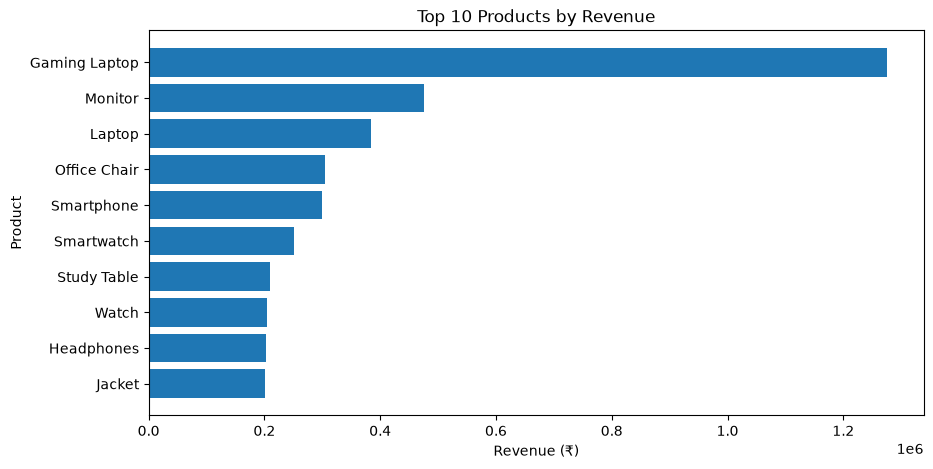

In [83]:
top_10_products = product_revenue.head(10)
print(top_10_products)

top_products = (
    orders.groupby("product_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))
plt.barh(top_products.index, top_products.values)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")
plt.gca().invert_yaxis()
plt.show()

In [33]:
orders = orders.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)
print(orders.head())

   order_id  customer_id  product_id order_date  quantity payment_method  \
0      1001          130         138 2025-04-11         1    Net Banking   
1      1002          187         132 2025-05-10         2            UPI   
2      1003          129         115 2025-05-10         2    Credit Card   
3      1004          160         129 2025-09-04         2            UPI   
4      1005          184         115 2025-09-12         3            UPI   

   price  revenue  product_name          category_x          category_y  \
0    249      249       Pen Set  Books & Stationery  Books & Stationery   
1   7500    15000   Study Table           Furniture           Furniture   
2   6500    13000  External SSD         Electronics         Electronics   
3   4999     9998         Watch         Accessories         Accessories   
4   6500    19500  External SSD         Electronics         Electronics   

             category  
0  Books & Stationery  
1           Furniture  
2         Electronic

In [35]:
category_revenue = orders.groupby("category")["revenue"].sum()
category_revenue = category_revenue.sort_values(ascending=False)
print(category_revenue)

category
Electronics           3917100
Furniture              963100
Clothing               823305
Home & Kitchen         484403
Accessories            455631
Books & Stationery     248387
Name: revenue, dtype: int64


In [50]:
#category with highest revenue
print(category_revenue.idxmax())
print(orders.head())

Electronics
   order_id  customer_id  product_id order_date  quantity payment_method  \
0      1001          130         138 2025-04-11         1    Net Banking   
1      1002          187         132 2025-05-10         2            UPI   
2      1003          129         115 2025-05-10         2    Credit Card   
3      1004          160         129 2025-09-04         2            UPI   
4      1005          184         115 2025-09-12         3            UPI   

   price  revenue  product_name          category_x          category_y  \
0    249      249       Pen Set  Books & Stationery  Books & Stationery   
1   7500    15000   Study Table           Furniture           Furniture   
2   6500    13000  External SSD         Electronics         Electronics   
3   4999     9998         Watch         Accessories         Accessories   
4   6500    19500  External SSD         Electronics         Electronics   

             category        name_x        name_y          name  
0  Books & Sta

In [58]:
#Which customers are spending the most?
customer_revenue = orders.groupby(["customer_id", "name"])["revenue"].idxmax()
customer_revenue = customer_revenue.sort_values(ascending=True)
top_10_customers = customer_revenue.head(10)
print(customer_revenue.head(10))

customer_id  name        
187          Riya Verma       1
160          Anjali Gupta     3
184          Neha Verma       4
185          Pooja Verma     10
153          Tanya Gupta     17
189          Aditi Verma     18
24           Neha Sharma     26
176          Raj Verma       32
57           Harsh Singh     34
49           Vikram Singh    38
Name: revenue, dtype: int64


In [ ]:
#we will print every detail of top customer
top_customers = top_10_customers.reset_index()

top_customers = top_customers.merge(
    customers[["customer_id", "name", "city", "state"]],
    on="customer_id",
    how="left"
)
print(top_customers)

   customer_id        name_x  revenue        name_y       city           state
0          187    Riya Verma        1    Riya Verma   Ludhiana          Punjab
1          160  Anjali Gupta        3  Anjali Gupta     Indore  Madhya Pradesh
2          184    Neha Verma        4    Neha Verma  Ahmedabad         Gujarat
3          185   Pooja Verma       10   Pooja Verma     Jaipur       Rajasthan
4          153   Tanya Gupta       17   Tanya Gupta     Jaipur       Rajasthan
5          189   Aditi Verma       18   Aditi Verma    Lucknow   Uttar Pradesh
6           24   Neha Sharma       26   Neha Sharma  Ahmedabad         Gujarat
7          176     Raj Verma       32     Raj Verma     Indore  Madhya Pradesh
8           57   Harsh Singh       34   Harsh Singh     Jaipur       Rajasthan
9           49  Vikram Singh       38  Vikram Singh      Delhi           Delhi


2025-10
1010601


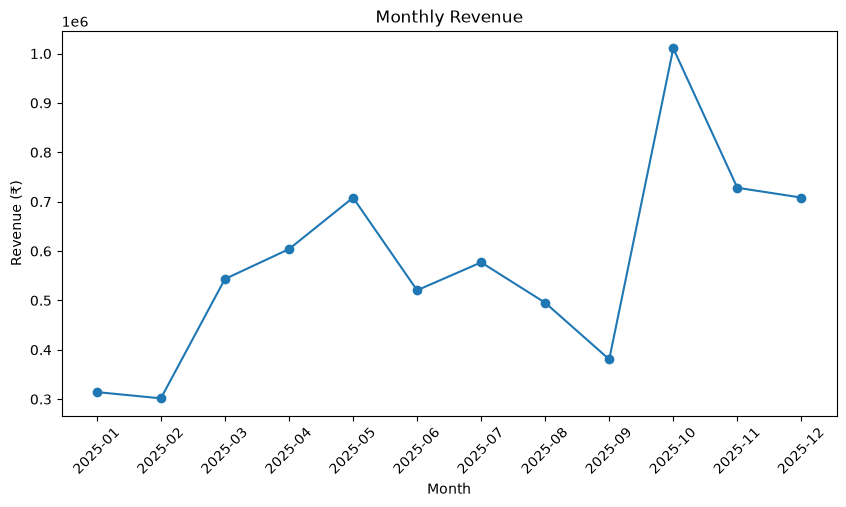

In [75]:
#adding month column to order
orders["month"] = orders["order_date"].dt.to_period("M")
monthly_revenue = orders.groupby("month")["revenue"].sum()
monthly_revenue = monthly_revenue.sort_index()
print(monthly_revenue.idxmax())
print(monthly_revenue.max())


#Montly Revenue line chart
plt.figure(figsize=(10, 5))

plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values, marker="o")

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)

plt.show()

category
Electronics           3917100
Furniture              963100
Clothing               823305
Home & Kitchen         484403
Accessories            455631
Books & Stationery     248387
Name: revenue, dtype: int64


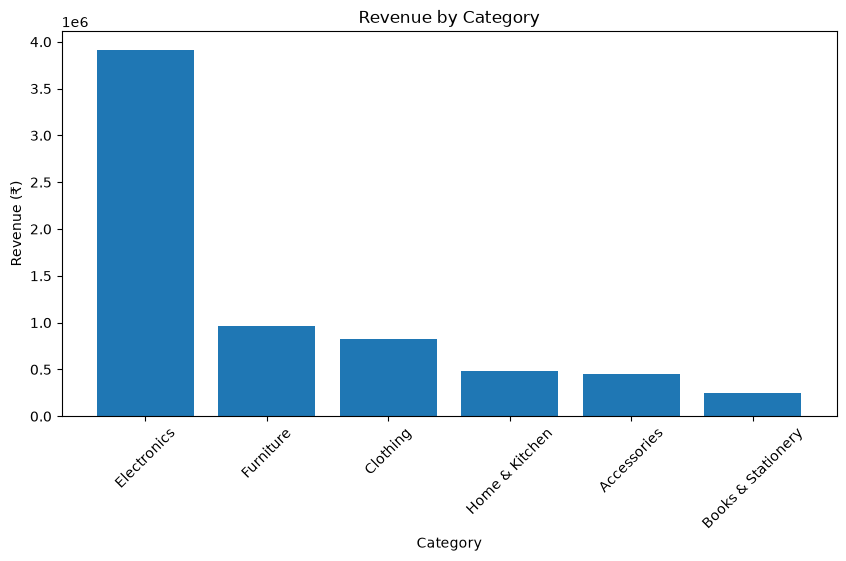

category
Electronics           56.84
Furniture             13.97
Clothing              11.95
Home & Kitchen         7.03
Accessories            6.61
Books & Stationery     3.60
Name: revenue, dtype: float64


In [76]:
#Category Revenue
category_revenue = orders.groupby("category")["revenue"].sum()
category_revenue = category_revenue.sort_values(ascending=False)

print(category_revenue)

#Category Revenue chart
plt.figure(figsize=(10, 5))

plt.bar(category_revenue.index, category_revenue.values)

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)

plt.show()

#calculate each category's percentage of total revenue
    
category_percentage = (
    category_revenue / category_revenue.sum() * 100
).round(2)

print(category_percentage)

payment_method
Cash on Delivery     99
Credit Card         220
Debit Card          161
Net Banking          79
UPI                 441
Name: order_id, dtype: int64
payment_method
UPI                 2828142
Debit Card          1402615
Credit Card         1278922
Cash on Delivery     858587
Net Banking          523660
Name: revenue, dtype: int64


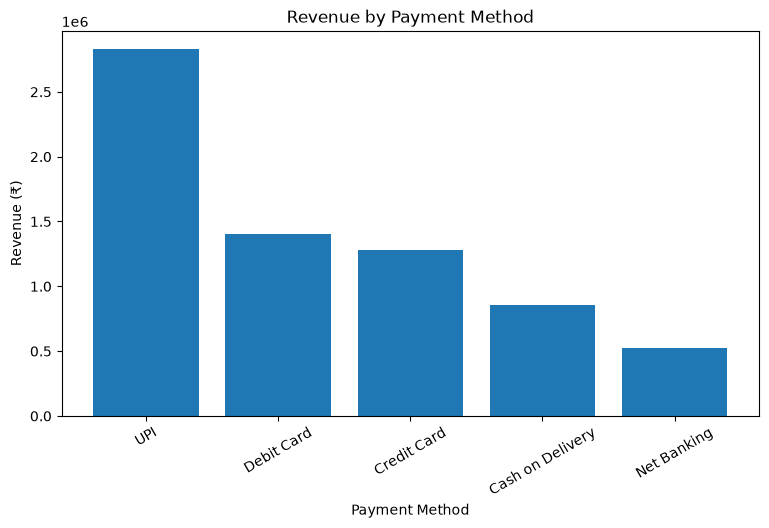

In [80]:
#Count orders by payment method
payment_orders = orders.groupby("payment_method")["order_id"].count()
print(payment_orders)

#Revenue by payment method
payment_revenue = orders.groupby("payment_method")["revenue"].sum()
payment_revenue = payment_revenue.sort_values(ascending=False)

print(payment_revenue)

#bar chart of payment_revenue
plt.figure(figsize=(9, 5))

plt.bar(payment_revenue.index, payment_revenue.values)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=30)

plt.show()
